# Supplementary figures and tables

This notebook produces only the assembled supplementary figures and the LaTeX tables
of the supplementary information. Panels are drawn by the same fitting code as the
corresponding single plots in `combined_plots.ipynb`; where a figure groups many
panels, only the figure handling differs.

Two things are deliberately not here. Figure S2 (association kinetics) is left out,
because the repository holds kinetics data for ethylene glycol only. Figure S16 is
**not** the version shown in the current supplementary PDF: it now uses the same
n*beta model as the main text, described in its own section below.

## Setup

In [1]:
%matplotlib inline

import os
import re
import string
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import uncertainties as unc
from lmfit import Model
from matplotlib.image import imread
from matplotlib.ticker import ScalarFormatter
from scipy.optimize import curve_fit
from uncertainties import umath
from uncertainties import unumpy as unp

import utils as uts
from main_data_processor import Data

In [2]:
equillibrium_constans_path = 'source_data/MacromoleculeEquilibria_Crowding'
complexation_data_path = 'source_data/IonCrowderComplexation/raw_data'
sodium_path = 'source_data/IonStrengthDependency/Na_FRET.csv'

all_data = Data(
    equillibrium_constans_path,
    complexation_data_path,
    sodium_path
)

complexation_data = all_data.EquillbriumConstantsObj
equillibrium_constants = all_data.SodiumCrowderComplexationObj

# Permanent master dataframe used throughout the notebook.
# Do not overwrite this variable in analysis-specific cells.
data = all_data.data.copy()

os.makedirs('./plots', exist_ok=True)

In [3]:
# styles
styles = {
    'buffer': {'x': [0], 'y': [1760000000], 'yerr': [311872000], 'color': '#868788', 'marker': '*', 'ms': 9.5, 'mec': '#000000', 'label': 'buffer'},
    'EGly': {'color': '#2d642a', 'marker': '.', 'ms': 14, 'mec': '#000000', 'label': 'EG'},
    'PEG200': {'color': '#b3daff', 'marker': 'd', 'ms': 8, 'mec': '#000000', 'label': 'PEG 200'},
    'PEG400': {'color': '#640024', 'marker': '^', 'ms': 8, 'mec': '#000000', 'label': 'PEG 400'},
    'PEG600': {'color': '#ff730f', 'marker': 'h', 'ms': 8.5, 'mec': '#000000', 'label': 'PEG 600'},
    'PEG1000': {'color': '#fed85d', 'marker': 'P', 'ms': 8, 'mec': '#000000', 'label': 'PEG 1k'},
    'PEG1500': {'color': '#142cd7', 'marker': 'p', 'ms': 8.5, 'mec': '#000000', 'label': 'PEG 1.5k'},
    'PEG3000': {'color': '#ac1416', 'marker': 's', 'ms': 6.5, 'mec': '#000000', 'label': 'PEG 3k'},
    'PEG6000': {'color': '#674ea7', 'marker': 'D', 'ms': 6, 'mec': '#000000', 'label': 'PEG 6k'},
    'PEG12000': {'color': '#709d74', 'marker': 'v', 'ms': 8, 'mec': '#000000', 'label': 'PEG 12k'},
    'PEG20000': {'color': '#00cccc', 'marker': 'X', 'ms': 8, 'mec': '#000000', 'label': 'PEG 20k'},
    'PEG35000': {'color': '#b28092', 'marker': 'H', 'ms': 8.5, 'mec': '#000000', 'label': 'PEG 35k'},
    'Dextran6000': {'color': '#ff2f4e', 'marker': '<', 'ms': 8, 'mec': '#000000', 'label': 'Dextran 6k'},
    'Dextran70000': {'color': '#bf94e4', 'marker': '>', 'ms': 8, 'mec': '#000000', 'label': 'Dextran 70k'},
    'Ficoll400000': {'color': '#dfb37f', 'marker': '*', 'ms': 10, 'mec': '#000000', 'label': 'Ficoll 400k'},
}

In [4]:
def quad_model(x, a0, a1, a2):
    return a0 + a1 * x + a2 * x**2


def extract_name_and_value_from_a_file(filename):
    base_name = os.path.splitext(filename)[0]
    parts = base_name.split('_')

    if len(parts) == 2 and 'p' in parts[1]:
        name = parts[0]
        number1, number2 = parts[1].split('p')
        value = float(f"{int(number1)}.{int(number2)}")
        return name, value, base_name

    return None, None, None


def make_K_fitting(alfa, gamma, v0, n=1):
    def K_fitting(x, K, D):
        sqrt_term = np.sqrt(
            ((-x / n - D - 1 / K)**2)
            - 4 * x / n * D
        )
        term1 = D - 0.5 * (
            x / n + D + 1 / K - sqrt_term
        )
        term2 = 1 + (gamma / alfa) * K * (
            x / n
            - 0.5 * (x / n + D + 1 / K - sqrt_term)
        )
        return alfa * v0 * term1 * term2

    return K_fitting


def crowder_name_sort_key(name):
    if name == 'EGly':
        return (0, 0)

    match = re.search(r'PEG(\d+)', name)
    if match:
        return (1, int(match.group(1)))

    return (2, name)


def compute_effective_donor_concentration(wt_percent, C_nominal=1e-8):
    rho_water = 0.99707
    rho_mix = 0.99707 + 0.0017441 * wt_percent

    V_water = 0.2 / rho_water
    m_mix = 0.2 / (100 - wt_percent) * 100
    V_mix = m_mix / rho_mix

    volume_factor = V_mix / V_water
    return C_nominal / volume_factor


def save_grouped_plot_images(plot_files, output_path, n_cols=3):
    n_files = len(plot_files)
    if n_files == 0:
        return

    n_rows = (n_files + n_cols - 1) // n_cols

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(5 * n_cols, 4.5 * n_rows)
    )
    axes = np.atleast_1d(axes).flatten()
    letters = list(string.ascii_lowercase)

    for i, (ax, file) in enumerate(zip(axes, plot_files)):
        img = imread(os.path.join('plots', file))
        ax.imshow(img)
        ax.axis('off')
        ax.text(
            0.02,
            1.03,
            f"{letters[i]}",
            transform=ax.transAxes,
            fontsize=15,
            fontweight='bold',
            va='top',
            ha='left'
        )

    for ax in axes[n_files:]:
        ax.axis('off')

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, transparent=True)
    plt.close()


def plot_styled_crowder_errorbars(
    plot_dataframe,
    x_column,
    y_column,
    *,
    positive_x=False,
    positive_y=False,
    nonzero_columns=(),
    positive_columns=()
):
    for crowder, style in styles.items():
        if crowder == 'buffer':
            continue

        crowder_df = plot_dataframe[
            plot_dataframe['crowder'] == crowder
        ].copy()

        required_columns = [
            x_column,
            y_column,
            *nonzero_columns,
            *positive_columns
        ]
        crowder_df = crowder_df.dropna(
            subset=required_columns
        )

        if crowder_df.empty:
            continue

        x = crowder_df[x_column].astype(float).values

        y, y_err = uts.get_float_uncertainty(
            crowder_df[y_column]
        )
        y = np.asarray(y, dtype=float)
        y_err = np.asarray(y_err, dtype=float)

        valid = (
            np.isfinite(x)
            & np.isfinite(y)
            & np.isfinite(y_err)
        )

        if positive_x:
            valid &= x > 0

        if positive_y:
            valid &= y > 0

        for column in nonzero_columns:
            values = crowder_df[column].astype(float).values
            valid &= np.isfinite(values) & (values != 0)

        for column in positive_columns:
            values = crowder_df[column].astype(float).values
            valid &= np.isfinite(values) & (values > 0)

        x = x[valid]
        y = y[valid]
        y_err = y_err[valid]

        if len(x) == 0:
            continue

        order = np.argsort(x)
        x = x[order]
        y = y[order]
        y_err = y_err[order]

        plt.errorbar(
            x,
            y,
            yerr=y_err,
            color=style['color'],
            marker=style['marker'],
            mfc=style['color'],
            mec=style['mec'],
            linestyle='none',
            lw=1,
            ms=style['ms'],
            elinewidth=1,
            capsize=3,
            capthick=1,
            label=style['label']
        )


def plot_styled_crowder_points(
    plot_dataframe,
    x_column,
    y_column,
    *,
    positive_x=False,
    positive_y=False
):
    for crowder, style in styles.items():
        if crowder == 'buffer':
            continue

        crowder_df = plot_dataframe[
            plot_dataframe['crowder'] == crowder
        ].dropna(
            subset=[x_column, y_column]
        ).copy()

        if crowder_df.empty:
            continue

        x = crowder_df[x_column].astype(float).values
        y = crowder_df[y_column].astype(float).values

        valid = np.isfinite(x) & np.isfinite(y)

        if positive_x:
            valid &= x > 0

        if positive_y:
            valid &= y > 0

        x = x[valid]
        y = y[valid]

        if len(x) == 0:
            continue

        order = np.argsort(x)
        x = x[order]
        y = y[order]

        plt.plot(
            x,
            y,
            color=style['color'],
            marker=style['marker'],
            mfc=style['color'],
            mec=style['mec'],
            linestyle='none',
            ms=style['ms'],
            label=style['label']
        )

In [5]:
project_root = Path.cwd()
ri_module_dir = (
    project_root
    / 'source_data'
    / 'MacromoleculeEquilibria_Crowding'
    / 'our_raw_results'
)
output_dir = project_root / 'plots'
output_dir.mkdir(parents=True, exist_ok=True)

if str(ri_module_dir) not in sys.path:
    sys.path.insert(0, str(ri_module_dir))

from ssDNA_hybdrization_equillibrium_constant import (
    calculate_RI_slope_with_error
)

_cwd = Path.cwd()
os.chdir(ri_module_dir)
try:
    df_RI = calculate_RI_slope_with_error()
finally:
    os.chdir(_cwd)

directory = (
    project_root
    / 'source_data'
    / 'MacromoleculeEquilibria_Crowding'
    / 'our_raw_results'
    / 'DNA-DNA_countrate_vs_crowder_concentration'
)

/media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/.venv/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/.venv/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/.venv/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/.venv/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpect

## Figure and table helpers

In [6]:
from uncertainties import UFloat

# Supplementary figures are assembled from panels of the standard single-plot size,
# so that fonts and markers match the figures of the main manuscript.
PANEL_W, PANEL_H = 7, 5.6
PANEL_LABEL_KW = dict(fontsize=26, fontweight='bold', va='bottom', ha='right')

si_dir = project_root / 'publication_plots' / 'supplementary'
si_dir.mkdir(parents=True, exist_ok=True)

# Crowders in the order used throughout the supplementary information.
SI_CROWDERS = ['EGly', 'PEG200', 'PEG400', 'PEG600', 'PEG1000', 'PEG1500',
               'PEG3000', 'PEG6000', 'PEG12000', 'PEG20000', 'PEG35000']


def label_panel(ax, letter, x=None):
    """Put a bold panel letter above the left edge of an axes, in figure coordinates.

    Call it after the layout is final, so that letters line up between rows.
    """
    fig = ax.get_figure()
    box = ax.get_position()
    x = box.x0 if x is None else x
    fig.text(x - 0.45 / fig.get_figwidth(), box.y1 + 0.10 / fig.get_figheight(),
             letter, **PANEL_LABEL_KW)
    return x


def grid_figure(n_panels, n_cols=3):
    """Open a figure with room for `n_panels` panels and hide the unused slots."""
    n_rows = int(np.ceil(n_panels / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(n_cols * PANEL_W, n_rows * PANEL_H))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n_panels:]:
        ax.set_axis_off()
    return fig, axes[:n_panels]


def finish_figure(fig, axes, name):
    """Add panel letters after the layout is final, then save as PNG and PDF."""
    fig.tight_layout()

    if len(axes) > 1:
        for ax, letter in zip(axes, string.ascii_lowercase):
            label_panel(ax, letter)

    for extension in ('png', 'pdf'):
        fig.savefig(si_dir / f'{name}.{extension}', dpi=300,
                    transparent=True, bbox_inches='tight')
    print(f'saved {si_dir / name}.png and .pdf')


def save_table(latex, name):
    """Write a LaTeX table next to the supplementary figures and echo it."""
    path = si_dir / f'{name}.tex'
    path.write_text(latex)
    print(f'saved {path}\n')
    print(latex)


def ufloat_to_latex(x, digits=2):
    """Format a value with uncertainty for a LaTeX table cell."""
    if isinstance(x, UFloat):
        return rf'${x.n:.{digits}f}\pm{x.s:.{digits}f}$'
    return str(x)

## Figure S1 - refractive index of the crowder solutions

In [7]:
def figure_S1(ax):
    """Figure S1 - refractive index of the crowder solutions.

    Panel body taken from combined_plots.ipynb, cell 8.
    """
    plt.sca(ax)

    # Refractive index vs crowder wt.%
    # Linear fits constrained through RI = 1.337 at 0 wt.%

    ri_module_dir = (
        project_root
        / 'source_data'
        / 'MacromoleculeEquilibria_Crowding'
        / 'our_raw_results'
    )

    output_dir = project_root / 'plots'
    output_dir.mkdir(parents=True, exist_ok=True)

    if str(ri_module_dir) not in sys.path:
        sys.path.insert(0, str(ri_module_dir))

    from ssDNA_hybdrization_equillibrium_constant import (
        calculate_average_RI_with_error_of_sample
    )

    # Averaged RI values and replicate standard deviations generated
    # with the same repository function used by the K analysis
    ri_average = calculate_average_RI_with_error_of_sample()

    ri_crowders = [
        'EGly',
        'PEG200',
        'PEG400',
        'PEG600',
        'PEG1000',
        'PEG1500',
        'PEG3000',
        'PEG6000',
        'PEG12000',
        'PEG20000',
        'PEG35000'
    ]

    # Fixed common reference point used in the original plotting code
    x_reference = 0.0
    ri_reference = 1.337


    for crowder in ri_crowders:

        if crowder not in styles:
            continue

        style = styles[crowder]

        # The repository function returns strings such as:
        # "1.34523±0.00004"
        ri_strings = ri_average[crowder].astype(str)

        values = pd.to_numeric(
            ri_strings.str.split('±').str[0],
            errors='coerce'
        ).to_numpy(dtype=float)

        errors = pd.to_numeric(
            ri_strings.str.split('±').str[1],
            errors='coerce'
        ).to_numpy(dtype=float)

        concentrations = pd.to_numeric(
            ri_average['wt_%'],
            errors='coerce'
        ).to_numpy(dtype=float)

        valid = (
            np.isfinite(concentrations)
            & np.isfinite(values)
            & np.isfinite(errors)
        )

        x = concentrations[valid]
        y = values[valid]
        y_err = errors[valid]

        if len(x) < 2:
            print(f'Skipping {crowder}: fewer than two valid points')
            continue

        order = np.argsort(x)

        x = x[order]
        y = y[order]
        y_err = y_err[order]

        # --------------------------------------------------------------
        # Linear least-squares fit constrained through:
        # x = 0 wt.%, RI = 1.337
        #
        # Model:
        # RI = slope * (x - x_reference) + ri_reference
        # --------------------------------------------------------------

        x_shifted = x - x_reference
        y_shifted = y - ri_reference

        denominator = np.sum(x_shifted**2)

        if denominator == 0:
            print(f'Skipping {crowder}: invalid concentration range')
            continue

        slope = np.sum(x_shifted * y_shifted) / denominator

        y_predicted = (
            slope * (x - x_reference)
            + ri_reference
        )

        residual_sum_squares = np.sum(
            (y - y_predicted)**2
        )

        total_sum_squares = np.sum(
            (y - np.mean(y))**2
        )

        if total_sum_squares > 0:
            r_squared = 1 - residual_sum_squares / total_sum_squares
        else:
            r_squared = np.nan

        x_fit = np.linspace(0, 42, 200)

        y_fit = (
            slope * (x_fit - x_reference)
            + ri_reference
        )

        # Fit line
        plt.plot(
            x_fit,
            y_fit,
            color=style['color'],
            linestyle='--',
            lw=1.5
        )

        # Experimental data
        plt.errorbar(
            x,
            y,
            yerr=y_err,
            color=style['color'],
            marker=style['marker'],
            mfc=style['color'],
            mec=style['mec'],
            linestyle='none',
            lw=1,
            ms=style['ms'],
            elinewidth=1,
            capsize=3,
            capthick=1,
            label=(
                f"{style['label']}, "
                f"R$^2$ = {r_squared:.3f}"
            )
        )

    # Plot the common reference point once
    plt.plot(
        x_reference,
        ri_reference,
        color=styles['buffer']['color'],
        marker=styles['buffer']['marker'],
        mfc=styles['buffer']['color'],
        mec=styles['buffer']['mec'],
        linestyle='none',
        ms=styles['buffer']['ms'],
        label='buffer'
    )

    plt.title(
        '$RI$ of crowder solutions',
        fontsize=20
    )

    plt.xlabel(
        'crowder wt.%',
        fontsize=17
    )

    plt.ylabel(
        '$RI$',
        fontsize=17
    )

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.xlim(-2, 42)

    plt.legend(
        frameon=True,
        loc='upper left',
        fontsize=8
    )

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS1.png and .pdf


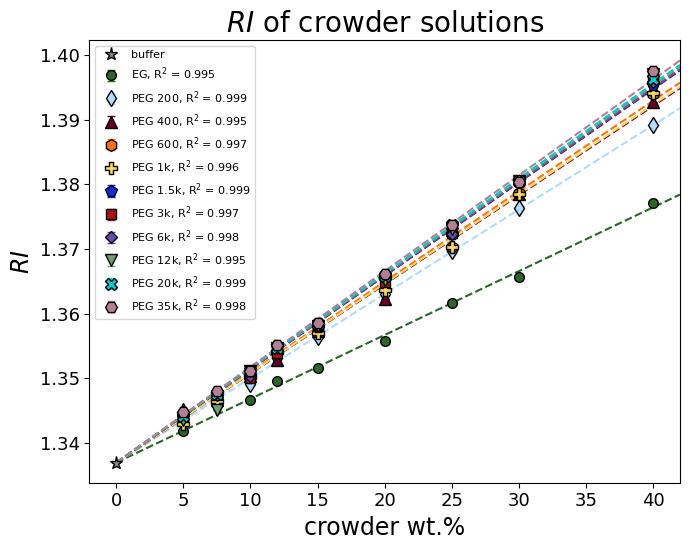

In [8]:
# Figure S1: refractive index of the crowder solutions
fig, axes = grid_figure(1, n_cols=1)

figure_S1(axes[0])

finish_figure(fig, axes, 'figureS1')
plt.show()

## Table S1 - measured refractive indices

In [9]:
# Table S1: measured refractive indices, mean +/- population standard deviation of
# four replicates. The values come from the same helper that feeds the K analysis.
from ssDNA_hybdrization_equillibrium_constant import (
    calculate_average_RI_with_error_of_sample
)

_cwd = Path.cwd()
os.chdir(ri_module_dir)
try:
    ri_table = calculate_average_RI_with_error_of_sample()
finally:
    os.chdir(_cwd)

# The helper returns "mean±std" strings; split them into a LaTeX-ready form.
ri_latex = ri_table.copy()

for crowder in SI_CROWDERS:
    ri_latex[crowder] = ri_latex[crowder].apply(
        lambda cell: '' if 'nan' in str(cell)
        else r'${}\pm{}$'.format(*str(cell).split('±'))
    )

ri_latex = ri_latex.rename(
    columns={crowder: styles[crowder]['label'] for crowder in SI_CROWDERS}
)
ri_latex = ri_latex.rename(columns={'wt_%': r'wt.\%'})

save_table(
    ri_latex.to_latex(index=False, escape=False,
                      column_format='l' + 'c' * (len(ri_latex.columns) - 1)),
    'tableS1'
)

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/tableS1.tex

\begin{tabular}{lccccccccccc}
\toprule
wt.\% & EG & PEG 200 & PEG 400 & PEG 600 & PEG 1k & PEG 1.5k & PEG 3k & PEG 6k & PEG 12k & PEG 20k & PEG 35k \\
\midrule
5.000000 & $1.34192\pm0.00000$ & $1.34377\pm0.00001$ & $1.34524\pm0.00009$ & $1.34383\pm0.00001$ & $1.34297\pm0.00000$ & $1.34449\pm0.00001$ & $1.34422\pm0.00001$ & $1.34425\pm0.00000$ & $1.34362\pm0.00000$ & $1.34424\pm0.00003$ & $1.34481\pm0.00001$ \\
7.500000 & $1.34590\pm0.00001$ & $1.34626\pm0.00000$ & $1.34661\pm0.00001$ & $1.34668\pm0.00001$ & $1.34654\pm0.00001$ & $1.34763\pm0.00001$ & $1.34748\pm0.00001$ & $1.34741\pm0.00000$ & $1.34519\pm0.00001$ & $1.34757\pm0.00001$ & $1.34812\pm0.00000$ \\
10.000000 & $1.34667\pm0.00001$ & $1.34912\pm0.00002$ & $1.35033\pm0.00002$ & $1.35075\pm0.00001$ & $1.35017\pm0.00000$ & $1.35103\pm0.00001$ & $1.35013\pm0.00000$ & $1.35044\pm0.00001$ & $1.35119\pm0.00001$ & $1.35109\pm0.0000

## Figure S3 - equilibrium constant vs cation concentration

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS3.png and .pdf


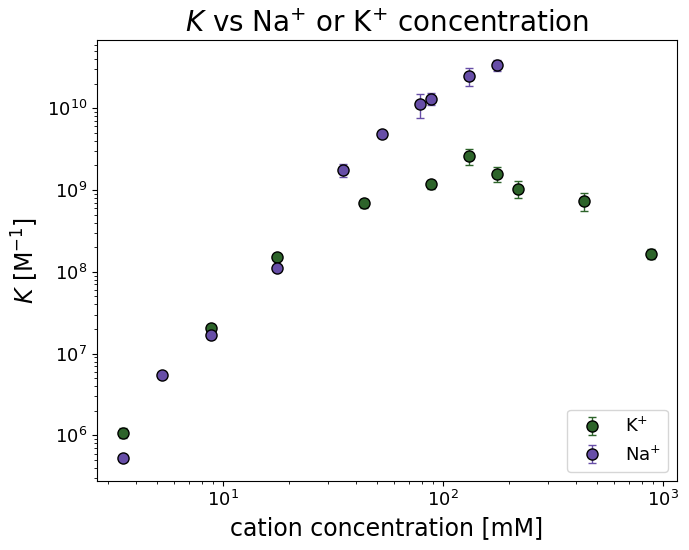

In [10]:
# Figure S3: DNA-DNA equilibrium constant vs monovalent cation concentration
# Sodium and potassium were measured in the same buffer series, so both are shown
# on one log-log axes.
ion_source = pd.read_csv(project_root / sodium_path)

cation_series = [
    ('K$^{+}$', 'C_K+_[mM]', 'K_K+', 'K_err_K+', styles['EGly']),
    ('Na$^{+}$', 'C_Na+_[mM]', 'K_Na+_[1/M]', 'K_err_Na+_[1/M]', styles['PEG6000']),
]

fig, axes = grid_figure(1, n_cols=1)
ax = axes[0]
plt.sca(ax)

for label, x_column, y_column, err_column, style in cation_series:
    if x_column not in ion_source.columns:
        continue

    series = ion_source[[x_column, y_column, err_column]].dropna()

    plt.errorbar(series[x_column], series[y_column], yerr=series[err_column],
                 color=style['color'], marker='o', mfc=style['color'],
                 mec=style['mec'], linestyle='none', lw=1, ms=8,
                 elinewidth=1, capsize=3, capthick=1, label=label)

# --- Formatting ---
plt.title(r'$K$ vs Na$^{+}$ or K$^{+}$ concentration', fontsize=20)
plt.xlabel('cation concentration [mM]', fontsize=17)
plt.ylabel(r'$K$ [M$^{-1}$]', fontsize=17)
plt.xscale('log')
plt.yscale('log')
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.legend(frameon=True, loc='lower right', fontsize=13)

finish_figure(fig, axes, 'figureS3')
plt.show()

## Table S2 - source data for Figure S3

In [11]:
# Table S2: source data behind Figure S3
ion_latex = ion_source.copy()

for column in ion_latex.columns:
    ion_latex[column] = ion_latex[column].apply(
        lambda value: '' if pd.isna(value)
        else (f'{value:.1f}' if 'C_' in column else f'{value:.2e}')
    )

# Column names are renamed rather than passed as `header=`, because pandas runs
# header strings through str.format() and LaTeX braces break it.
ion_latex = ion_latex.rename(columns={
    'C_K+_[mM]': r'$C_{\mathrm{K}^+}$ [mM]',
    'K_K+': r'$K_{\mathrm{K}^+}$ [M$^{-1}$]',
    'K_err_K+': r'$K_{\mathrm{err,K}^+}$ [M$^{-1}$]',
    'C_Na+_[mM]': r'$C_{\mathrm{Na}^+}$ [mM]',
    'K_Na+_[1/M]': r'$K_{\mathrm{Na}^+}$ [M$^{-1}$]',
    'K_err_Na+_[1/M]': r'$K_{\mathrm{err,Na}^+}$ [M$^{-1}$]',
})

save_table(
    ion_latex.to_latex(index=False, escape=False, column_format='cccccc'),
    'tableS2'
)

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/tableS2.tex

\begin{tabular}{cccccc}
\toprule
$C_{\mathrm{K}^+}$ [mM] & $K_{\mathrm{K}^+}$ [M$^{-1}$] & $K_{\mathrm{err,K}^+}$ [M$^{-1}$] & $C_{\mathrm{Na}^+}$ [mM] & $K_{\mathrm{Na}^+}$ [M$^{-1}$] & $K_{\mathrm{err,Na}^+}$ [M$^{-1}$] \\
\midrule
3.5 & 1.08e+06 & 1.55e+05 & 3.5 & 5.28e+05 & 3.65e+04 \\
8.8 & 2.08e+07 & 7.74e+05 & 5.3 & 5.54e+06 & 3.08e+05 \\
17.5 & 1.50e+08 & 9.39e+06 & 8.8 & 1.68e+07 & 1.78e+06 \\
43.9 & 6.90e+08 & 8.76e+07 & 17.5 & 1.11e+08 & 6.65e+06 \\
87.7 & 1.18e+09 & 1.52e+08 & 35.1 & 1.76e+09 & 3.12e+08 \\
131.6 & 2.59e+09 & 5.50e+08 & 52.6 & 4.81e+09 & 4.29e+08 \\
175.4 & 1.58e+09 & 3.24e+08 & 87.7 & 1.30e+10 & 2.21e+09 \\
219.2 & 1.04e+09 & 2.34e+08 & 131.6 & 2.49e+10 & 6.05e+09 \\
438.5 & 7.35e+08 & 1.83e+08 & 175.4 & 3.34e+10 & 5.04e+09 \\
877.0 & 1.66e+08 & 2.17e+07 & 78.9 & 1.12e+10 & 3.71e+09 \\
\bottomrule
\end{tabular}



## Figures S4-S14 - K fits, one figure per crowder

In [12]:
def draw_K_fit(ax, filename):
    """Draw one donor-count-rate titration and its K fit into `ax`.

    Same fit as the single plots of combined_plots.ipynb, cell 9; only the figure
    handling differs, because here the panels share one supplementary figure.
    """
    plt.sca(ax)

    crowder_name, wt_percent, base_name = extract_name_and_value_from_a_file(filename)

    df = pd.read_csv(directory / filename)
    RI = wt_percent * df_RI.at[crowder_name, 'slope'] + df_RI.at[crowder_name, 'intercept']
    z_correction = RI / 1.333  # RI_water

    # Constants
    C_Don = compute_effective_donor_concentration(wt_percent, C_nominal=1e-8)
    alfa = df['a'][0]
    gamma = alfa * df['y'][0]
    v0 = 6.02e23 * 1e-16 * 10 * df['Vef_[fl]'][0] * z_correction
    n = 1

    x = df['ratio'] * C_Don
    y = df['value']
    xx = np.linspace(0, x.max(), 500)

    # Fitting function
    K_fitting = make_K_fitting(alfa, gamma, v0, n)

    model = Model(K_fitting)
    model.set_param_hint('K', value=1e6, min=1e2, max=5e13)
    model.set_param_hint('D', value=1e-8, min=1.1e-9, max=2e-8)
    result = model.fit(y, x=x)

    fitK = result.params['K'].value
    fitKerr = result.params['K'].stderr
    fitD = result.params['D'].value

    # Use model-derived uncertainty
    y_model_uncertainty = result.eval_uncertainty(x=x)

    # Plot
    style = styles[crowder_name]
    plt.errorbar(x * 10**9, y, yerr=y_model_uncertainty, fmt=style['marker'], ms=style['ms'],
                 color=style['color'], mec=style['mec'], label='data',
                 elinewidth=1.2, capsize=3)

    plt.plot(xx * 10**9, K_fitting(xx, fitK, fitD),
             label=fr'{style["label"]} fit: $K = ({fitK:.1e} \pm {fitKerr:.1e})$ M$^{{-1}}$',
             color=style['color'], linestyle='--', lw=2)

    plt.xlabel(r'$C_{DNA}$ (acceptor) [nM]', fontsize=17)
    plt.ylabel('donor count rate [cps]', fontsize=17)
    plt.title(f'$K$ fit for {style["label"]} ({wt_percent:.1f} wt.%)', fontsize=20)
    plt.legend(fontsize=11, frameon=True)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)


def K_fit_files_by_crowder():
    """Group the titration files by crowder, each sorted by crowder concentration.

    Titrations at 50 wt.% and above are left out, matching the `crowder wt. [%] < 50`
    filter applied to the master dataframe everywhere else in the analysis. At those
    concentrations the duplex signal is lost and the fit no longer converges.
    """
    grouped = defaultdict(list)

    for filename in os.listdir(directory):
        if not filename.endswith('.csv'):
            continue

        crowder_name, wt_percent, _ = extract_name_and_value_from_a_file(filename)
        if not crowder_name or crowder_name not in styles:
            continue

        if wt_percent >= 50:
            continue

        grouped[crowder_name].append((wt_percent, filename))

    return {crowder: [name for _, name in sorted(files)]
            for crowder, files in grouped.items()}

In [13]:
# Figures S4-S14: one supplementary figure of K fits per crowder
K_fit_files = K_fit_files_by_crowder()

for number, crowder in enumerate(SI_CROWDERS, start=4):
    files = K_fit_files.get(crowder, [])
    if not files:
        print(f'no titration files for {crowder}')
        continue

    fig, axes = grid_figure(len(files), n_cols=3)

    for ax, filename in zip(axes, files):
        draw_K_fit(ax, filename)

    finish_figure(fig, axes, f'figureS{number}')
    plt.close(fig)

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS4.png and .pdf


saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS5.png and .pdf


saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS6.png and .pdf


saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS7.png and .pdf


saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS8.png and .pdf


...

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS10.png and .pdf


saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS11.png and .pdf


saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS12.png and .pdf


saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS13.png and .pdf


saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS14.png and .pdf


## Table S3 - equilibrium constants and free energies

In [14]:
# Table S3: equilibrium constants and standard free energies for every crowder
# and concentration, laid out crowder by crowder.
equilibrium_table = data.copy()

blocks = []
for crowder in SI_CROWDERS:
    block = equilibrium_table[equilibrium_table['crowder'] == crowder].copy()
    if block.empty:
        continue

    block = block.sort_values('crowder wt. [%]')

    K_value, K_error = uts.get_float_uncertainty(block['K_uf [M]'])
    dG_value, dG_error = uts.get_float_uncertainty(block['dG_exp_[kJ/mol]'])

    blocks.append(pd.DataFrame({
        'crowder': styles[crowder]['label'],
        r'$c$ [wt.\%]': [f'{value:.1f}' for value in block['crowder wt. [%]']],
        r'$K$ [M$^{-1}$]': [f'{value:.2e}' for value in K_value],
        r'$K_{\mathrm{err}}$ [M$^{-1}$]': [f'{value:.2e}' for value in K_error],
        r'$\Delta G^{\circ}$ [kJ mol$^{-1}$]': [f'{value:.2f}' for value in dG_value],
        r'$\Delta G^{\circ}_{\mathrm{err}}$ [kJ mol$^{-1}$]': [f'{value:.2f}' for value in dG_error],
    }))

equilibrium_latex = pd.concat(blocks, ignore_index=True)

save_table(
    equilibrium_latex.to_latex(index=False, escape=False, column_format='lccccc'),
    'tableS3'
)

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/tableS3.tex

\begin{tabular}{lccccc}
\toprule
crowder & $c$ [wt.\%] & $K$ [M$^{-1}$] & $K_{\mathrm{err}}$ [M$^{-1}$] & $\Delta G^{\circ}$ [kJ mol$^{-1}$] & $\Delta G^{\circ}_{\mathrm{err}}$ [kJ mol$^{-1}$] \\
\midrule
EG & 0.0 & 1.76e+09 & 3.12e+08 & -52.77 & 0.44 \\
EG & 2.5 & 1.78e+09 & 2.31e+08 & -52.80 & 0.32 \\
EG & 5.0 & 6.75e+08 & 4.20e+07 & -50.40 & 0.15 \\
EG & 7.5 & 1.78e+09 & 1.66e+08 & -52.80 & 0.23 \\
EG & 10.0 & 4.83e+08 & 2.50e+07 & -49.57 & 0.13 \\
EG & 12.5 & 1.22e+09 & 2.76e+08 & -51.87 & 0.56 \\
EG & 15.0 & 3.57e+08 & 1.48e+07 & -48.82 & 0.10 \\
EG & 20.0 & 2.18e+08 & 1.19e+07 & -47.60 & 0.14 \\
EG & 25.0 & 1.08e+08 & 6.18e+06 & -45.85 & 0.14 \\
EG & 30.0 & 5.77e+07 & 5.59e+06 & -44.30 & 0.24 \\
EG & 40.0 & 4.60e+06 & 4.45e+05 & -38.03 & 0.24 \\
EG & 50.0 & 1.08e+04 & 9.34e+04 & -23.03 & 21.33 \\
PEG 200 & 0.0 & 1.76e+09 & 3.12e+08 & -52.77 & 0.44 \\
PEG 200 & 2.5 & 3.46e+09 &

## Figure S15 - molecular crowding fits

In [15]:
def draw_mc_fit(ax, crowder):
    """Draw the phenomenological molecular-crowding fit of one crowder into `ax`.

    Same fit as the single plots of combined_plots.ipynb, cell 16.
    """
    plt.sca(ax)

    style = styles[crowder]
    experimental_data = data.copy()

    df = experimental_data[experimental_data['crowder'] == crowder]

    # Data for plotting
    x = df['crowder wt. [%]'].values
    y, y_err = uts.get_float_uncertainty(df['K_uf [M]'])
    log_y = np.log(y)

    # Fit for plotting (in wt.%)
    popt, pcov = curve_fit(quad_model, x, log_y)
    a0, a1, a2 = popt
    a0_err, a1_err, a2_err = np.sqrt(np.diag(pcov))

    # Fit for legend (in M)
    x_M = df['concentration [M]'].values
    popt_M, _ = curve_fit(quad_model, x_M, log_y)
    a0_M, a1_M, a2_M = popt_M

    # Add buffer point
    buffer_style = styles['buffer']
    plt.errorbar(buffer_style['x'], buffer_style['y'], yerr=buffer_style['yerr'],
                 color=buffer_style['color'], marker=buffer_style['marker'],
                 mec=buffer_style['mec'], linestyle='none', lw=1,
                 ms=buffer_style['ms'], elinewidth=1, capsize=3, capthick=1,
                 label=f'{buffer_style["label"]} data')

    # Plot data points
    plt.errorbar(x, y, yerr=y_err,
                 color=style['color'], marker=style['marker'],
                 mec=style['mec'], linestyle='none', lw=1, ms=style['ms'],
                 elinewidth=1, capsize=3, capthick=1, label=f'{style["label"]} data')

    # Generate smooth x and compute fit + uncertainty
    x_parabola = np.linspace(0, np.max(x) + 3, 200)
    lnK_fit = a0 + a1 * x_parabola + a2 * x_parabola**2
    lnK_err = np.sqrt(a0_err**2 + (x_parabola**2) * a1_err**2 + (x_parabola**4) * a2_err**2)

    # Convert to K and bounds
    K_fit = np.exp(lnK_fit)
    K_upper = np.exp(lnK_fit + lnK_err)
    K_lower = np.exp(lnK_fit - lnK_err)

    # Plot fit and uncertainty band
    plt.plot(x_parabola, K_fit, color=style['color'], linestyle='--', lw=1.5,
             label=f'fit: ln$K$ = {a0_M:.1f} + {a1_M:.1f}x [M$^{{-1}}$] + {a2_M:.1f}x$^2$ [M$^{{-2}}$]')
    plt.fill_between(x_parabola, K_lower, K_upper, color=style['color'], alpha=0.2,
                     label='uncertainty band')

    # Formatting
    plt.title(f'molecular crowding fit for {style["label"]}', fontsize=20)
    plt.xlabel('crowder concentration [wt.%]', fontsize=17)
    plt.ylabel(r'$K$ [M$^{-1}$]', fontsize=17)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.yscale('log')
    plt.legend(frameon=True, loc='lower left', fontsize=11)
    plt.xlim(-3, np.max(x) + 3)

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS15.png and .pdf


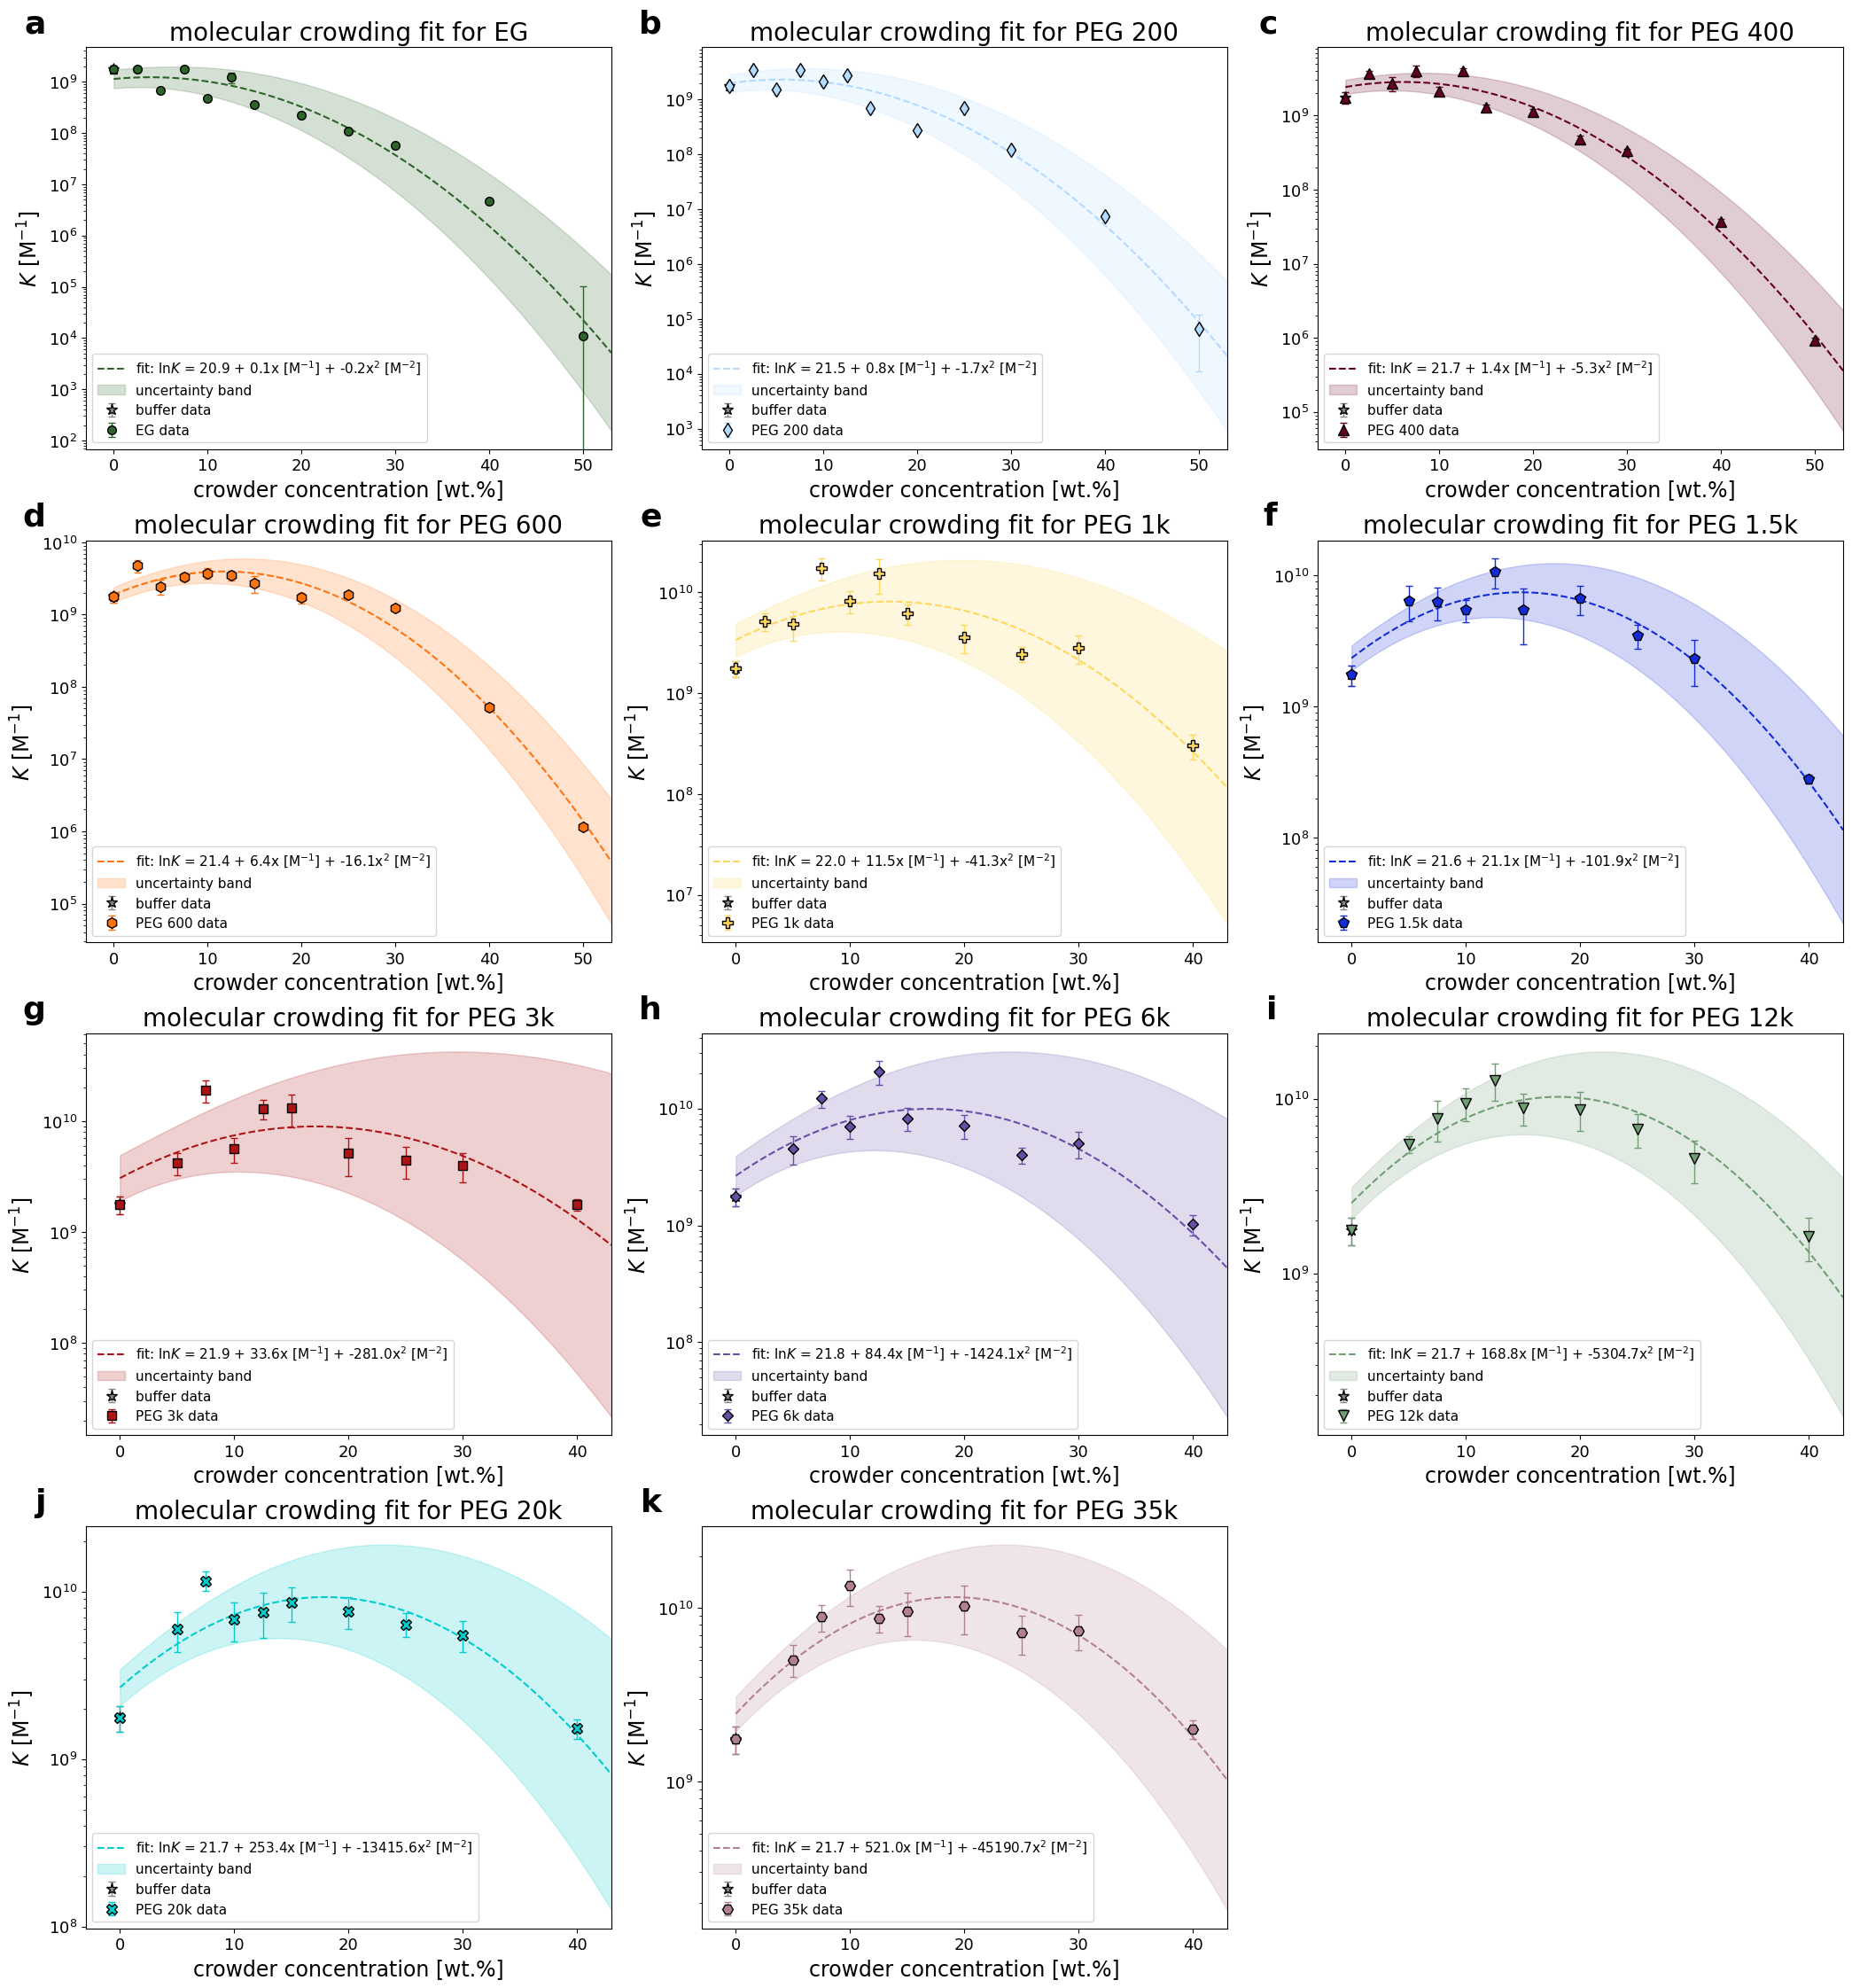

In [16]:
# Figure S15: molecular crowding fits for all measured crowders
fig, axes = grid_figure(len(SI_CROWDERS), n_cols=3)

for ax, crowder in zip(axes, SI_CROWDERS):
    draw_mc_fit(ax, crowder)

finish_figure(fig, axes, 'figureS15')
plt.show()

## Table S4 - molecular crowding coefficients

In [17]:
# Table S4: fitted coefficients of the molecular crowding model
coefficients = (
    all_data.EquillbriumConstantsObj.analyzed_data
    .sort_values(by='MW_[g/mol]')[['crowder', 'a2_exp', 'a1_exp', 'a0_exp']]
    .drop_duplicates()
    .reset_index(drop=True)
)

coefficients_latex = coefficients.copy()
for column in ['a2_exp', 'a1_exp', 'a0_exp']:
    coefficients_latex[column] = coefficients_latex[column].apply(ufloat_to_latex)

save_table(
    coefficients_latex.to_latex(
        index=False, escape=False, column_format='lccc',
        header=['Crowder', r'$a_2$', r'$a_1$', r'$a_0$']
    ),
    'tableS4'
)

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/tableS4.tex

\begin{tabular}{lccc}
\toprule
Crowder & $a_2$ & $a_1$ & $a_0$ \\
\midrule
EGly & $-0.07\pm0.03$ & $-0.27\pm0.20$ & $20.88\pm0.30$ \\
PEG200 & $-1.18\pm0.41$ & $-0.11\pm1.00$ & $21.54\pm0.55$ \\
PEG400 & $-5.20\pm0.62$ & $1.34\pm0.89$ & $21.66\pm0.28$ \\
PEG600 & $-17.91\pm1.04$ & $8.12\pm1.12$ & $21.26\pm0.26$ \\
PEG1000 & $-41.94\pm10.98$ & $11.76\pm4.32$ & $21.85\pm0.32$ \\
PEG1500 & $-104.79\pm9.68$ & $22.65\pm3.16$ & $21.48\pm0.18$ \\
PEG3000 & $-331.08\pm96.17$ & $43.94\pm15.22$ & $21.66\pm0.40$ \\
PEG6000 & $-1385.76\pm384.22$ & $80.26\pm27.77$ & $21.80\pm0.40$ \\
PEG12000 & $-5684.82\pm888.02$ & $181.05\pm29.66$ & $21.65\pm0.18$ \\
PEG20000 & $-13566.17\pm3038.43$ & $252.20\pm70.01$ & $21.85\pm0.30$ \\
PEG35000 & $-47097.45\pm6731.72$ & $556.18\pm90.76$ & $21.59\pm0.21$ \\
\bottomrule
\end{tabular}



## Figure S16 - n*beta fits

The earlier version of this figure plotted a linearized form of the complexation
model, obtained from a Taylor expansion of the diffusion function and drawn against
the logarithm of the monomer concentration, with two variants depending on the order
of the expansion. That version is superseded.

The figure below fits the model directly, in the form given in Supplementary Note S6:

$$D_w = \frac{D_{\mathrm{Na}^+} + D_{[\mathrm{NaL}_n]^+}\,\beta n\, c_L}{1 + \beta n\, c_L},$$

where $D_{\mathrm{Na}^+}$ is the free-sodium diffusivity **corrected for the
nanoviscosity of the crowder solution** rather than its value in buffer, and
$D_{[\mathrm{NaL}_n]^+}$ is taken as the crowder diffusivity. The buffer point is
plotted for reference but excluded from every fit, since it contains no crowder.

Captions and axis descriptions therefore need updating: the x-axis is now the crowder
concentration in wt.%, the y-axis is the measured sodium diffusivity $D_w$, and the
fitted quantity is $\beta n$ itself rather than a slope of a linearized relation.

In [18]:
def draw_beta_fit(ax, crowder):
    """Draw the n*beta fit of one crowder into `ax`.

    This is the current model: the measured sodium diffusivity is described by

        D_w = (D_Na+ + D_[NaLn]+ * n*beta * c_L) / (1 + n*beta * c_L),

    where D_Na+ is the free-sodium diffusivity already corrected for the
    nanoviscosity of the crowder solution and D_[NaLn]+ is taken as the crowder
    diffusivity. The earlier supplementary figure showed a linearized form of this
    relation, obtained from a Taylor expansion and plotted against ln(c_L); that
    version is superseded by the fit below, which is the one used in the main text.
    """
    plt.sca(ax)

    style = styles[crowder]

    crowder_data = all_data.SodiumCrowderComplexationObj.analyzed_data.copy()
    crowder_data = crowder_data.loc[crowder_data['crowder'] == crowder].copy()

    # The buffer row carries no crowder and is excluded from the fit.
    crowder_data = crowder_data.loc[
        (crowder_data['concentration [M]'].astype(float) > 0)
        & (crowder_data['wt_%'].astype(float) > 0)
    ].sort_values('wt_%')

    x_data = crowder_data['concentration [M]'].astype(float).to_numpy()
    wt_data = crowder_data['wt_%'].astype(float).to_numpy()

    y_data, y_err = uts.get_float_uncertainty(crowder_data['D_Na_uf_[um2/s]'])
    y_data = np.asarray(y_data, dtype=float)
    y_err = np.asarray(y_err, dtype=float)

    # Free-sodium diffusivity corrected for nanoviscosity
    D_Na = crowder_data['D_Na_[um2/s] corr'].astype(float).to_numpy()

    D_crowder, _ = uts.get_float_uncertainty(crowder_data['D_crowder_uf_[um2/s]'])
    D_crowder = np.asarray(D_crowder, dtype=float)

    valid = (np.isfinite(x_data) & np.isfinite(wt_data) & np.isfinite(y_data)
             & np.isfinite(y_err) & np.isfinite(D_Na) & np.isfinite(D_crowder)
             & (x_data > 0) & (y_err > 0))

    x_data, wt_data = x_data[valid], wt_data[valid]
    y_data, y_err = y_data[valid], y_err[valid]
    D_Na, D_crowder = D_Na[valid], D_crowder[valid]

    def beta_fit_model(x, beta_n):
        return (D_Na + D_crowder * beta_n * x) / (1 + beta_n * x)

    popt, pcov = curve_fit(beta_fit_model, x_data, y_data, p0=[1.0],
                           sigma=y_err, bounds=(0, np.inf), maxfev=100000)

    beta_n = float(popt[0])
    beta_n_err = float(np.sqrt(np.diag(pcov))[0])

    # Smooth curve: the crowder diffusivity is interpolated over the same range
    a, b, c, _ = uts.exponential_fit_with_r_squared(wt_data, D_crowder)

    wt_fit = np.linspace(wt_data.min(), wt_data.max(), 500)
    x_fit = wt_fit / np.mean(wt_data / x_data)
    D_Na_fit = np.interp(wt_fit, wt_data, D_Na)
    D_crowder_fit = uts.exponential_model(wt_fit, a, b, c)

    y_fit = (D_Na_fit + D_crowder_fit * beta_n * x_fit) / (1 + beta_n * x_fit)

    plt.plot(wt_fit, y_fit, color=style['color'], linestyle='--', lw=1.5,
             label=rf'fit: $\beta n = {beta_n:.2f} \pm {beta_n_err:.2f}$ M$^{{-1}}$')

    plt.errorbar(wt_data, y_data, yerr=y_err,
                 color=style['color'], marker=style['marker'],
                 mfc=style['color'], mec=style['mec'],
                 linestyle='none', lw=1, ms=style['ms'],
                 elinewidth=1, capsize=3, capthick=1,
                 label=f'{style["label"]} data')

    # The buffer point is shown for reference but was not used in the fit.
    buffer_style = styles['buffer']
    plt.errorbar([0], [1425.622636], yerr=[57.95748743],
                 color=buffer_style['color'], marker=buffer_style['marker'],
                 mfc=buffer_style['color'], mec=buffer_style['mec'],
                 linestyle='none', lw=1, ms=buffer_style['ms'],
                 elinewidth=1, capsize=3, capthick=1, label=buffer_style['label'])

    # Formatting
    plt.title(rf'$\beta n$ fit for {style["label"]}', fontsize=20)
    plt.xlabel('crowder wt.%', fontsize=17)
    plt.ylabel(r'$D_w$ [$\mu$m$^2$/s]', fontsize=17)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.xlim(-0.5, wt_data.max() + 1)
    plt.legend(frameon=True, loc='upper right', fontsize=11)

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/figureS16.png and .pdf


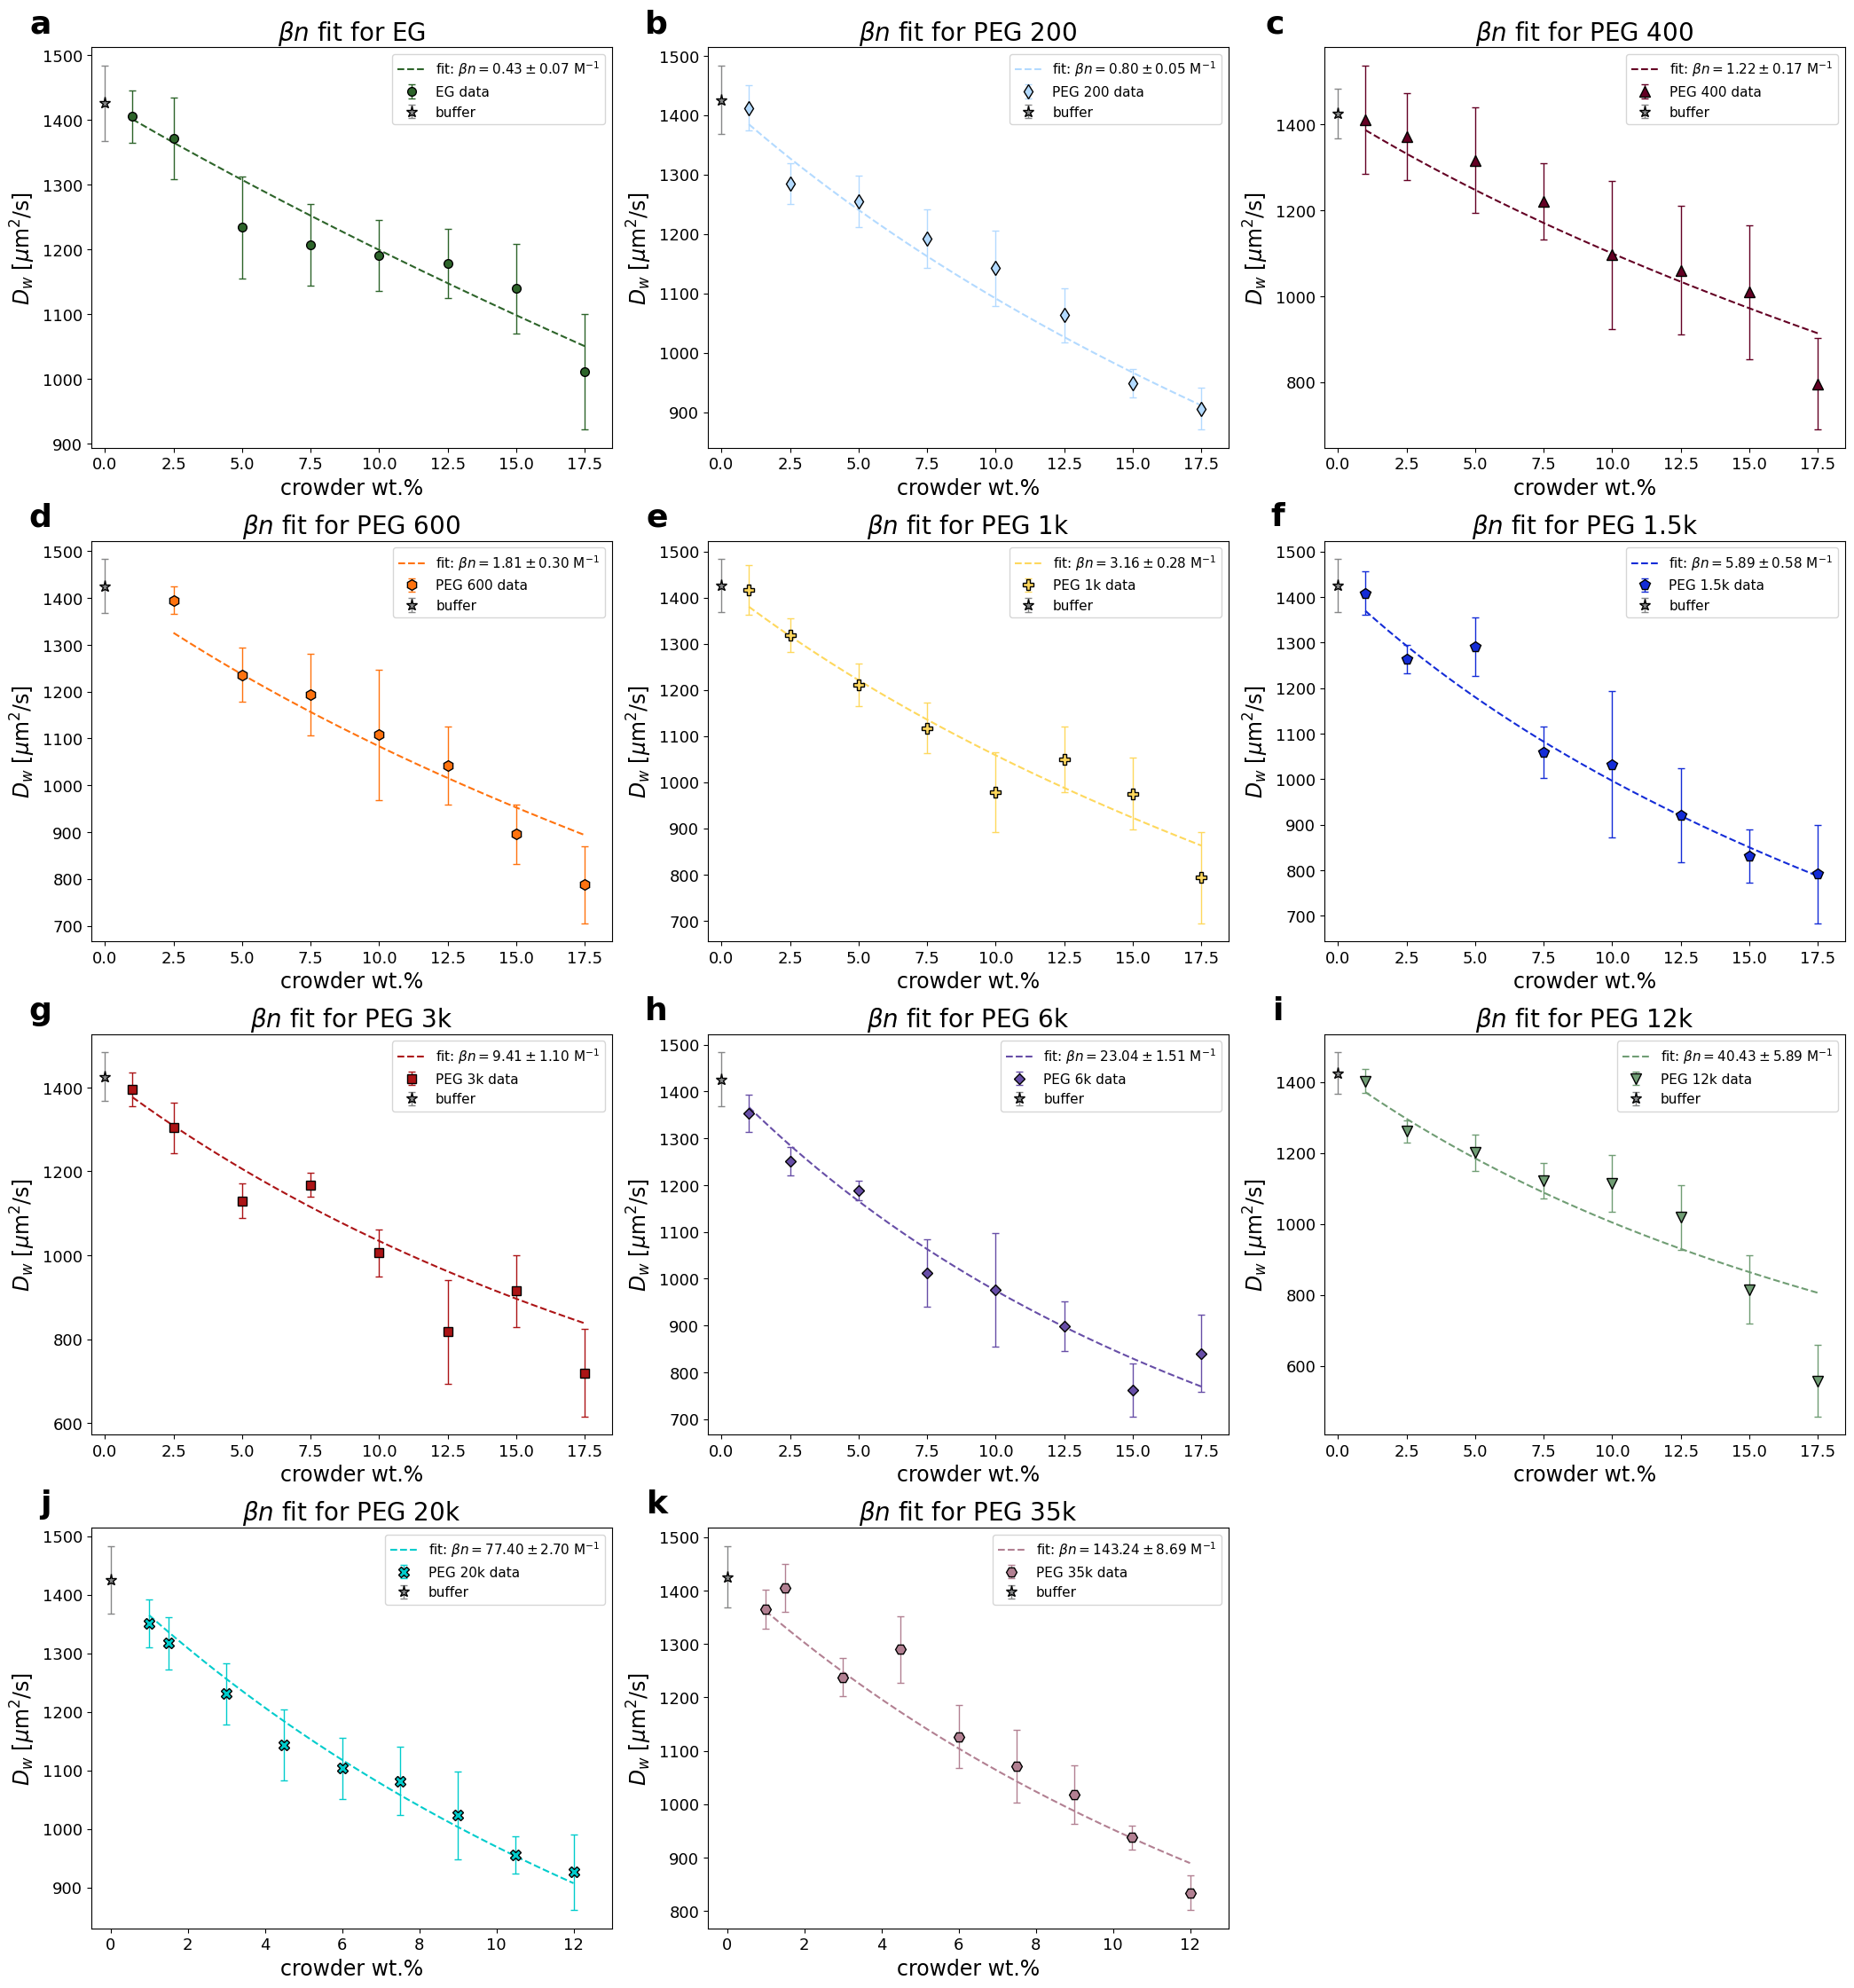

In [19]:
# Figure S16: n*beta fits for all measured crowders
fig, axes = grid_figure(len(SI_CROWDERS), n_cols=3)

for ax, crowder in zip(axes, SI_CROWDERS):
    draw_beta_fit(ax, crowder)

finish_figure(fig, axes, 'figureS16')
plt.show()

## Table S5 - fitted n*beta values

In [20]:
# Table S5: fitted n*beta for every crowder. The values come from the shared
# processor, which runs the same fit as Figure S16, so table and figure agree.
beta_values = (
    all_data.SodiumCrowderComplexationObj.analyzed_data
    .sort_values(by='MW_[g/mol]')[['crowder', 'n Beta [1/M]']]
    .drop_duplicates()
    .reset_index(drop=True)
)

beta_latex = beta_values.copy()
beta_latex['n Beta [1/M]'] = beta_latex['n Beta [1/M]'].apply(ufloat_to_latex)

save_table(
    beta_latex.to_latex(
        index=False, escape=False, column_format='lc',
        header=['Crowder', r'$\beta n$ [1/M]']
    ),
    'tableS5'
)

saved /media/dysk/IChF/stała_równowagi_w_zatłoczeniu_pegami/publication_plots/supplementary/tableS5.tex

\begin{tabular}{lc}
\toprule
Crowder & $\beta n$ [1/M] \\
\midrule
EGly & $0.43\pm0.07$ \\
PEG200 & $0.80\pm0.05$ \\
PEG400 & $1.22\pm0.17$ \\
PEG600 & $1.81\pm0.30$ \\
PEG1000 & $3.16\pm0.28$ \\
PEG1500 & $5.89\pm0.58$ \\
PEG3000 & $9.41\pm1.10$ \\
PEG6000 & $23.04\pm1.51$ \\
PEG12000 & $40.43\pm5.89$ \\
PEG20000 & $77.40\pm2.70$ \\
PEG35000 & $143.24\pm8.69$ \\
\bottomrule
\end{tabular}

